# Training the diabetes risk model

This notebook trains the machine learning model used on the **AI Risk Model** page of the app.

**Goal:** estimate how likely a person is to have type 2 diabetes from a few numbers the app already knows.

**Dataset:** the Pima Indians Diabetes Database (National Institute of Diabetes and Digestive and Kidney Diseases).
It has 768 women aged 21 or older of Pima heritage, living near Phoenix, Arizona. `Outcome = 1` means diabetes by WHO criteria.

**What this notebook does**
1. Load and clean the data (some zeros are really missing values)
2. Look at how the main inputs differ between people with and without diabetes
3. Compare three models and two sets of inputs with cross-validation
4. Choose a cutoff that catches most people who have diabetes
5. Test the final model **once** on data it has never seen
6. Save the model as plain numbers (JSON) so the app does not need scikit-learn

> This is a learning project and a screening aid, not a medical tool.

In [1]:
import json
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Load the data

In [2]:
df = pd.read_csv("../data/pima_diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
counts = df["Outcome"].value_counts()
print(f"No diabetes: {counts[0]}  |  Diabetes: {counts[1]}  ({counts[1] / len(df):.0%} of people)")

No diabetes: 500  |  Diabetes: 268  (35% of people)


About 35% of people in this dataset have diabetes. That is much higher than in the general population,
so the model's percentages describe *this group*, not anyone's real-life chance.

## 2. Zeros that are really missing values

A glucose, blood pressure or BMI of 0 is impossible for a living person. These zeros mean "not measured".
If we left them as 0, the model would learn nonsense, so we turn them into missing values (`NaN`).

In [4]:
cannot_be_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros per column:")
print((df[cannot_be_zero] == 0).sum().to_string())

df[cannot_be_zero] = df[cannot_be_zero].replace(0, np.nan)

Zeros per column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11


Insulin is missing for almost half the people and skin thickness for about 30%, so those columns are weak.
Glucose and BMI are missing only a handful of times. We fill gaps with the **median** later, inside the model pipeline.

## 3. A first look

How do glucose, BMI and age compare between the two groups?

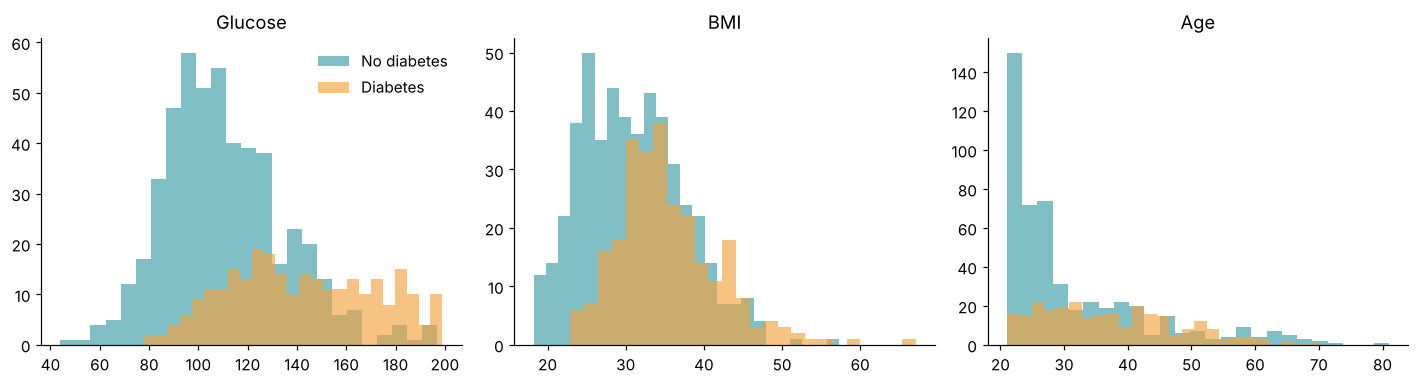

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    for outcome, color, label in [(0, "#3E9DA9", "No diabetes"), (1, "#F4A340", "Diabetes")]:
        ax.hist(df.loc[df["Outcome"] == outcome, col].dropna(), bins=25, alpha=0.65,
                color=color, label=label)
    ax.set_title(col)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

Glucose separates the groups the most. BMI and age help too.

## 4. Keep a test set aside

We put 20% of the data in a locked box (the **test set**). Every choice below (model, inputs, cutoff)
is made using only the other 80%. At the very end we open the box once to get an honest score.

In [6]:
ALL_FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
APP_FEATURES = ["Glucose", "BMI", "Age", "Pregnancies"]  # numbers the app can know

X = df[ALL_FEATURES]
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Training: {len(X_train)} people  |  Test: {len(X_test)} people")

Training: 614 people  |  Test: 154 people


## 5. Compare models with cross-validation

Cross-validation splits the training data into 5 parts, trains on 4 and scores on the 5th, five times.

We compare:
- **Logistic regression**: simple, and easy to explain
- **Random forest** and **gradient boosting**: more complex tree models

Each one is tried with **all 8 inputs** and with only the **4 inputs the app can know** (the app has no insulin or skin-fold test).

The main score is **ROC AUC**: the chance the model ranks a random person with diabetes above a random person without (0.5 = guessing, 1.0 = perfect).

In [7]:
def pipeline(model):
    # fill missing values, put inputs on the same scale, then fit the model
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for feature_name, features in [("All 8 inputs", ALL_FEATURES), ("4 app inputs", APP_FEATURES)]:
    for model_name, model in models.items():
        scores = cross_validate(pipeline(model), X_train[features], y_train, cv=cv,
                                scoring=["roc_auc", "accuracy"])
        rows.append({"Inputs": feature_name, "Model": model_name,
                     "ROC AUC": scores["test_roc_auc"].mean().round(3),
                     "AUC spread (std)": scores["test_roc_auc"].std().round(3),
                     "Accuracy": scores["test_accuracy"].mean().round(3)})

comparison = pd.DataFrame(rows)
comparison

,Inputs,Model,ROC AUC,AUC spread (std),Accuracy
0,All 8 inputs,Logistic regression,0.843,0.019,0.788
1,All 8 inputs,Random forest,0.834,0.021,0.769
2,All 8 inputs,Gradient boosting,0.821,0.015,0.756
3,4 app inputs,Logistic regression,0.842,0.016,0.783
4,4 app inputs,Random forest,0.830,0.024,0.772
5,4 app inputs,Gradient boosting,0.815,0.025,0.751


**What this shows**
- Using only the 4 app inputs costs very little compared with all 8.
- Logistic regression scores about as well as the tree models; the differences are smaller than the spread between folds.

So we choose **logistic regression with 4 inputs**. When a simple model is as good as a complex one, the simple one wins:
we can explain every prediction, and it is just a few numbers to save.

## 6. Choose the cutoff

The model gives a probability. We still need a **cutoff** to say "higher risk".

For screening, **missing someone with diabetes is worse than a false alarm** (a false alarm costs one blood test).
So we care most about **recall**: of the people who really have diabetes, what share does the model flag?

We pick the highest cutoff that still gives at least **80% recall**, using cross-validated predictions on the training data only.

Chosen cutoff: 0.27


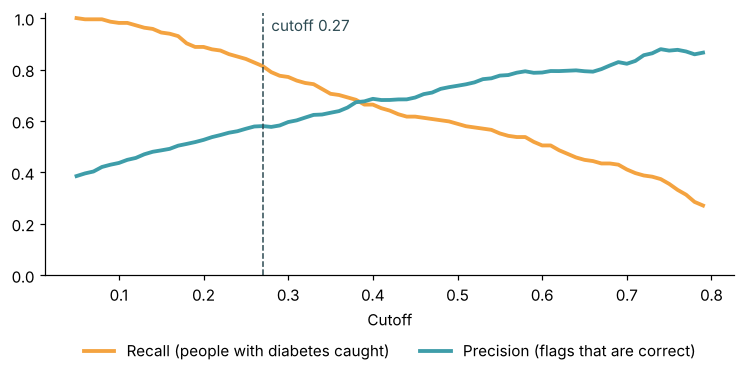

In [8]:
final_model = pipeline(LogisticRegression(max_iter=1000))
train_probs = cross_val_predict(final_model, X_train[APP_FEATURES], y_train, cv=cv,
                                method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.05, 0.80, 0.01), 2)
recalls = [recall_score(y_train, train_probs >= t) for t in thresholds]
precisions = [precision_score(y_train, train_probs >= t) for t in thresholds]

TARGET_RECALL = 0.80
threshold = max(t for t, r in zip(thresholds, recalls) if r >= TARGET_RECALL)
print(f"Chosen cutoff: {threshold:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(thresholds, recalls, color="#F4A340", lw=2.5, label="Recall (people with diabetes caught)")
ax.plot(thresholds, precisions, color="#3E9DA9", lw=2.5, label="Precision (flags that are correct)")
ax.axvline(threshold, color="#2C4A52", ls="--", lw=1)
ax.text(threshold + 0.01, 0.95, f"cutoff {threshold:.2f}", color="#2C4A52")
ax.set_xlabel("Cutoff")
ax.set_ylim(0, 1.02)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

Lowering the cutoff catches more people with diabetes (recall goes up) but raises more false alarms (precision goes down).
The dashed line is our choice.

## 7. Final test (opened once)

Now we train on all the training data and score on the test set the model has never seen.

In [9]:
final_model.fit(X_train[APP_FEATURES], y_train)
test_probs = final_model.predict_proba(X_test[APP_FEATURES])[:, 1]
test_pred = (test_probs >= threshold).astype(int)

metrics = {
    "roc_auc": round(roc_auc_score(y_test, test_probs), 3),
    "accuracy": round(accuracy_score(y_test, test_pred), 3),
    "recall": round(recall_score(y_test, test_pred), 3),
    "precision": round(precision_score(y_test, test_pred), 3),
}
cm = confusion_matrix(y_test, test_pred)
tn, fp, fn, tp = cm.ravel()
metrics["specificity"] = round(tn / (tn + fp), 3)

for name, value in metrics.items():
    print(f"{name:12s} {value:.3f}")

roc_auc      0.802
accuracy     0.721
recall       0.796
precision    0.573
specificity  0.680


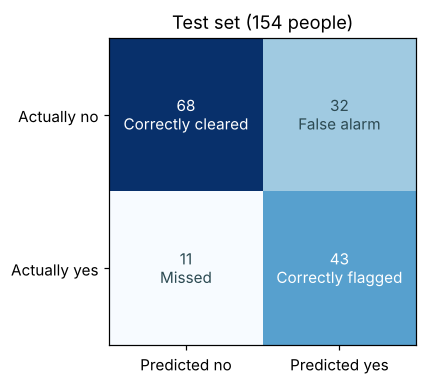

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
labels = [["Correctly cleared", "False alarm"], ["Missed", "Correctly flagged"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{labels[i][j]}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "#2C4A52")
ax.set_xticks([0, 1], ["Predicted no", "Predicted yes"])
ax.set_yticks([0, 1], ["Actually no", "Actually yes"])
ax.set_title("Test set (154 people)")
plt.tight_layout()
plt.show()

The test AUC is a little lower than the cross-validation AUC. With only 154 people in the test set, a gap of a few points is normal,
and the test number is the honest one to report.

On people it never saw, the model catches most of the diabetes cases, at the cost of some false alarms.
That is the trade-off we chose on purpose for a screening tool.

## 8. What the model learned

Logistic regression gives one weight per input. Because inputs were scaled, each weight shows the effect of
**one standard deviation** more of that input. The **odds ratio** is easier to read: above 1 raises the odds, below 1 lowers them.

In [11]:
scaler = final_model.named_steps["standardscaler"]
logreg = final_model.named_steps["logisticregression"]

weights = pd.DataFrame({
    "Input": APP_FEATURES,
    "One standard deviation =": [f"{s:.1f}" for s in scaler.scale_],
    "Weight": logreg.coef_[0].round(3),
    "Odds ratio per SD": np.exp(logreg.coef_[0]).round(2),
}).sort_values("Weight", ascending=False)
weights

,Input,One standard deviation =,Weight,Odds ratio per SD
0,Glucose,30.0,1.162,3.20
1,BMI,6.8,0.714,2.04
3,Pregnancies,3.3,0.353,1.42
2,Age,11.8,0.150,1.16


Glucose has by far the biggest effect, then BMI. Age and pregnancies add smaller amounts.

## 9. Save the model for the app

A logistic regression is just: scale each input, multiply by its weight, add them up, and squash with the sigmoid function.
So instead of saving a scikit-learn file (which can break when versions change), we save those numbers as JSON.
The app does the same maths with plain Python.

In [12]:
medians = final_model.named_steps["simpleimputer"].statistics_
export = {
    "name": "Diabetes risk model (logistic regression)",
    "trained_on": str(date.today()),
    "sklearn_version": sklearn.__version__,
    "features": APP_FEATURES,
    "mean": scaler.mean_.round(6).tolist(),
    "scale": scaler.scale_.round(6).tolist(),
    "coef": logreg.coef_[0].round(6).tolist(),
    "intercept": round(float(logreg.intercept_[0]), 6),
    "median": medians.round(3).tolist(),
    "threshold": float(threshold),
    "target_recall": TARGET_RECALL,
    "test_metrics": metrics,
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "cv_comparison": comparison.to_dict(orient="records"),
    "dataset": {
        "name": "Pima Indians Diabetes Database (NIDDK)",
        "rows": int(len(df)),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "share_with_diabetes": round(float(y.mean()), 3),
        "population": "Women aged 21+ of Pima heritage near Phoenix, Arizona",
    },
}
with open("../models/diabetes_model.json", "w") as f:
    json.dump(export, f, indent=2)
print("Saved ../models/diabetes_model.json")

Saved ../models/diabetes_model.json


**Check:** the plain-maths version must give exactly the same answers as scikit-learn.

In [13]:
def predict_plain(row, m=export):
    z = m["intercept"] + sum(c * (x - mu) / s for x, mu, s, c
                             in zip(row, m["mean"], m["scale"], m["coef"]))
    return 1 / (1 + np.exp(-z))

check = X_test[APP_FEATURES].fillna(dict(zip(APP_FEATURES, medians)))
plain = np.array([predict_plain(r) for r in check.to_numpy()])
biggest_gap = np.abs(plain - test_probs).max()
print(f"Largest difference from scikit-learn: {biggest_gap:.2e}")
assert biggest_gap < 1e-4

Largest difference from scikit-learn: 3.83e-07


## 10. Limitations (important)

- **Who is in the data:** only women of Pima heritage in Arizona, measured decades ago. Results may not carry over to
  other groups, including Indian adults, who often develop diabetes at a lower BMI. That is why the app shows this model
  only for female profiles and keeps the Indian Diabetes Risk Score (IDRS) alongside it.
- **The glucose input is different:** the dataset uses a 2-hour glucose tolerance test. The app uses the average of the
  user's after-meal readings, which is only a rough stand-in.
- **Glucose is partly how diabetes was diagnosed**, so it is naturally the strongest input.
- **Small dataset:** 768 people, 154 in the test set, so the scores could move by a few points with a different split.
- **The percentage is for this study group** (35% had diabetes), not a person's real-life chance.

Only a blood test (fasting glucose or HbA1c) can diagnose diabetes.